# Xử lý Dataset: Phân tích, Chia Stratified, và Cân bằng nhãn (Augmentation)
Notebook này thực hiện:
1. Lọc bỏ các ảnh không có vật thể (Background/Empty).
2. Thống kê và trực quan hóa phân bố các nhãn.
3. Chia tập Train (80%), Val (10%), Test (10%) đồng đều.
4. Tăng cường dữ liệu (Offline Data Augmentation) trên tập Train để xử lý mất cân bằng.

In [1]:
import os
import shutil
import random
from pathlib import Path
from collections import Counter
import numpy as np
import cv2
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Thiết lập thư mục
base_dir = r"e:\NCKH\Code\Fire_Smoke_Early-Detection\Final_Merged_Dataset"
images_dir = Path(base_dir) / "images"
labels_dir = Path(base_dir) / "labels"

output_dir = Path(r"e:\NCKH\Code\Fire_Smoke_Early-Detection\Dataset_Balanced_NoEmpty")
output_dir.mkdir(parents=True, exist_ok=True)

## 1. Các hàm hỗ trợ

In [2]:
def get_image_category_and_counts(label_path):
    if not os.path.exists(label_path):
        return -1, 0, 0
    
    c0 = 0
    c1 = 0
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                try:
                    cls_id = int(parts[0])
                    if cls_id == 0:
                        c0 += 1
                    elif cls_id == 1:
                        c1 += 1
                except ValueError:
                    pass
                    
    if c0 > 0 and c1 > 0:
        return 2, c0, c1 # Cả hai
    elif c0 > 0:
        return 0, c0, c1 # Chỉ có 0
    elif c1 > 0:
        return 1, c0, c1 # Chỉ có 1
    else:
        return -1, c0, c1 # Empty

def augment_image_and_label(img_path, label_path, dest_img_path, dest_label_path, aug_type):
    img = cv2.imread(str(img_path))
    if img is None: return False
        
    labels = []
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    labels.append([float(p) for p in parts[:5]])
                    
    new_labels = []
    if aug_type == 'hflip':
        img = cv2.flip(img, 1)
        for lbl in labels:
            cls_id, x, y, w, h = lbl
            new_x = 1.0 - x
            new_labels.append([cls_id, new_x, y, w, h])
    elif aug_type == 'brightness':
        factor = random.uniform(0.7, 1.3)
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        hsv = np.array(hsv, dtype=np.float64)
        hsv[:, :, 2] = hsv[:, :, 2] * factor
        hsv[:, :, 2][hsv[:, :, 2] > 255] = 255
        hsv = np.array(hsv, dtype=np.uint8)
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
        new_labels = labels
        
    cv2.imwrite(str(dest_img_path), img)
    with open(dest_label_path, 'w') as f:
        for lbl in new_labels:
            f.write(f"{int(lbl[0])} {lbl[1]:.6f} {lbl[2]:.6f} {lbl[3]:.6f} {lbl[4]:.6f}\n")
            
    return True

## 2. Thống kê và Lọc dữ liệu
Loại bỏ hoàn toàn các hình ảnh không chứa vật thể.

Đang xử lý ảnh...
Tổng số ảnh hợp lệ (có vật thể): 11437


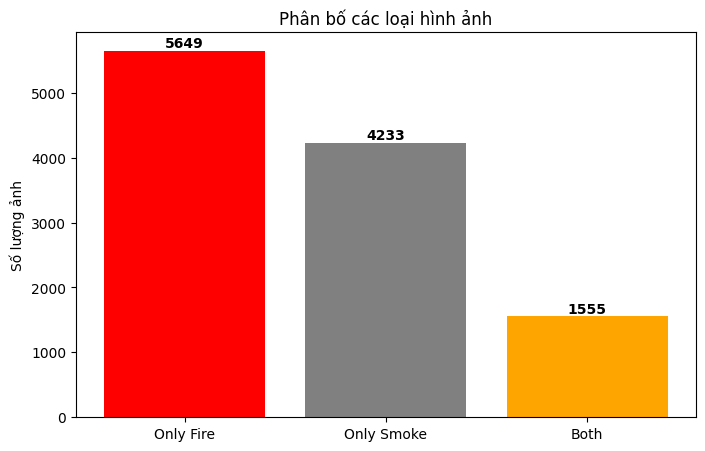

In [3]:
images = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'))]

categories = []
valid_images = []

print("Đang xử lý ảnh...")
for img_name in images:
    label_name = os.path.splitext(img_name)[0] + '.txt'
    label_path = labels_dir / label_name
    cat, _, _ = get_image_category_and_counts(label_path)
    
    if cat != -1: # BỎ QUA CÁC ẢNH EMPTY
        valid_images.append(img_name)
        categories.append(cat)

print(f"Tổng số ảnh hợp lệ (có vật thể): {len(valid_images)}")

cat_counts = Counter(categories)
labels_plot = ['Only Fire', 'Only Smoke', 'Both']
values_plot = [cat_counts[0], cat_counts[1], cat_counts[2]]

plt.figure(figsize=(8, 5))
plt.bar(labels_plot, values_plot, color=['red', 'gray', 'orange'])
plt.title('Phân bố các loại hình ảnh')
plt.ylabel('Số lượng ảnh')
for i, v in enumerate(values_plot):
    plt.text(i, v + 50, str(v), ha='center', fontweight='bold')
plt.show()

## 3. Chia tập Stratified (80/10/10)

In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(valid_images, categories, test_size=0.2, stratify=categories, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

print(f"Số lượng Train: {len(X_train)}")
print(f"Số lượng Val: {len(X_val)}")
print(f"Số lượng Test: {len(X_test)}")

splits = {
    'train': X_train,
    'val': X_val,
    'test': X_test
}

train_c0_bboxes = 0
train_c1_bboxes = 0
train_cat_1_images = []

for split_name, img_list in splits.items():
    split_img_dir = output_dir / split_name / "images"
    split_lbl_dir = output_dir / split_name / "labels"
    split_img_dir.mkdir(parents=True, exist_ok=True)
    split_lbl_dir.mkdir(parents=True, exist_ok=True)
    
    print(f"Copying {split_name} set...")
    for img_name in img_list:
        label_name = os.path.splitext(img_name)[0] + '.txt'
        src_img = images_dir / img_name
        src_lbl = labels_dir / label_name
        
        dest_img = split_img_dir / img_name
        dest_lbl = split_lbl_dir / label_name
        
        if src_img.exists():
            shutil.copy2(src_img, dest_img)
        if src_lbl.exists():
            shutil.copy2(src_lbl, dest_lbl)
            
        if split_name == 'train':
            cat, c0, c1 = get_image_category_and_counts(dest_lbl)
            train_c0_bboxes += c0
            train_c1_bboxes += c1
            if cat == 1:
                train_cat_1_images.append(img_name)

Số lượng Train: 9149
Số lượng Val: 1144
Số lượng Test: 1144
Copying train set...
Copying val set...
Copying test set...


## 4. Xử lý mất cân bằng (Augmentation) trên tập Train

In [5]:
print(f"[Trước Augmentation] Train BBoxes -> Class 0 (Fire): {train_c0_bboxes}, Class 1 (Smoke): {train_c1_bboxes}")
deficit = train_c0_bboxes - train_c1_bboxes

if deficit > 0:
    print(f"Class Smoke đang thiếu khoảng {deficit} bboxes. Tiến hành augmentation...")
    images_to_augment = random.choices(train_cat_1_images, k=deficit)
    
    train_img_dir = output_dir / 'train' / 'images'
    train_lbl_dir = output_dir / 'train' / 'labels'
    
    for i, img_name in enumerate(images_to_augment):
        label_name = os.path.splitext(img_name)[0] + '.txt'
        src_img = train_img_dir / img_name
        src_lbl = train_lbl_dir / label_name
        
        aug_type = random.choice(['hflip', 'brightness'])
        new_img_name = f"aug_{i}_{aug_type}_{img_name}"
        new_lbl_name = os.path.splitext(new_img_name)[0] + '.txt'
        
        dest_img = train_img_dir / new_img_name
        dest_lbl = train_lbl_dir / new_lbl_name
        
        success = augment_image_and_label(src_img, src_lbl, dest_img, dest_lbl, aug_type)
        if success:
            train_c1_bboxes += 1

    print(f"[Sau Augmentation] Train BBoxes -> Class 0 (Fire): {train_c0_bboxes}, Class 1 (Smoke): {train_c1_bboxes}")
    print("Dữ liệu đã được cân bằng!")
else:
    print("Dữ liệu đã cân bằng hoặc Lửa đang là thiểu số (Logic script mặc định tối ưu Khói).")

[Trước Augmentation] Train BBoxes -> Class 0 (Fire): 6825, Class 1 (Smoke): 5218
Class Smoke đang thiếu khoảng 1607 bboxes. Tiến hành augmentation...
[Sau Augmentation] Train BBoxes -> Class 0 (Fire): 6825, Class 1 (Smoke): 6825
Dữ liệu đã được cân bằng!
